<div style="padding:20px; border-radius:6px; background-color:#ffe6e6; color:#b30000; border-left:5px solid #b30000;">
<b>Jalankan notebook ini dengan environment <code>mandala_env</code>.</b><br/>
Siapkan <code>VAULT_TOKEN</code> di file <code>.env</code> pada <b>root workdir proyek Anda</b> (atau export di environment).
</div>

# Tutorial: Akses Data INACAWO via Mandala

Marine Data Lake (**Mandala**) menyimpan observasi MMS1 dan dataset model (termasuk INACAWO)
di object storage. Di Mandalahub, Anda membaca data lewat protokol **S3** sebagai
**Zarr / zcollection** — tanpa mengunduh file NetCDF utuh ke workspace.

Notebook ini melanjutkan materi OPeNDAP: fokus living archive, catalog Mandala,
lalu **case study briefing metocean Selat Sunda** yang sama (angin + gelombang + arus)
dengan layout operasional OFS.


## 1. Apa itu Mandala / Mandalahub / Zarr?

| Konsep | Arti singkat |
|---|---|
| **Data lake** | Penyimpanan fleksibel; data masuk tanpa wajib transform penuh dulu |
| **Mandala** | Data lake maritim BMKG (observasi + NWP) di S3 on-prem |
| **Zarr / zcollection** | Format chunked; baca hanya potongan yang dibutuhkan, cocok object storage |
| **Mandalahub** | JupyterHub analisis di jaringan lokal ke S3 Mandala |

Untuk INACAWO di Mandala: arsip **living FULL** cycle **00Z & 12Z** — ditumpuk / di-override
tiap cycle terbaru (bukan snapshot beku per run). Hindcast multi-dekade juga tersedia
lewat catalog `model_hindcast`.

**Bedakan dari OPeNDAP:** OPeNDAP = file NetCDF forecast retensi pendek + subset remote;
Mandala = arsip panjang + I/O paralel Zarr di Mandalahub.


## 2. Struktur data Mandala vs OPeNDAP

Keduanya berasal dari postproc ilmiah INACAWO yang sama, tetapi **kemasan berbeda**.
Selalu cek `.attrs` sebelum membandingkan angka antar sumber.

### Dimensi & naming
| | OPeNDAP | Mandala (contoh) |
|---|---|---|
| Waktu | `time` | `TSTEP` |
| Vertikal | `depth` (Flows) / — | `LAY` (layer; di WRF = level tekanan) |
| Spatials | `lat`, `lon` | `ROW`, `COL` (+ coord `lat`/`lon`) |
| SWH | `hs` | `sig_wave_height` |
| Wind U/V 10 m | `uwnd` / `vwnd` | `U_EASTWARD_10M` / `V_NORTHWARD_10M` (`inacawo_wrf_2d`) |
| Current | `u` / `v` | `u_sur_eastward` / `v_sur_northward` (atau `ubar_*`) |
| SSH | `zeta` | `zeta` |

### Collection yang dipakai di tutorial
| Path collection | Isi tipikal |
|---|---|
| `mandala-prod1/datalake/model/collections/inacawo_ocean_2d` | ocean/wave 2D surface fields |
| `mandala-prod1/datalake/model/collections/inacawo_wrf_2d` | atmosfer 2D (angin 10 m, MSLP, …) |
| `mandala-prod1/datalake/model/collections/inacawo_wrf_3d` | atmosfer 3D (level tekanan; **bukan** angin 10 m) |

### Satuan & arah (ingat!)
- Angin Mandala 10 m `U_EASTWARD_10M`/`V_NORTHWARD_10M` (`inacawo_wrf_2d`): **m/s** → `wind_in_mps=True`
  (sama level dengan OPeNDAP Atmos). Jangan pakai `U_WIND` dari `wrf_3d` (1000 hPa) untuk bandingkan `ws`.
- Arus Mandala `u_sur_*` / `ubar_*`: **m/s** → plot OFS pakai `current_in_mps=True`
  (beda dari OPeNDAP Flows yang biasanya **cm/s**).
- Gelombang `sig_wave_height`: **m**; `mean_wave_dir` dll.: derajat **meteorological coming from**
  (CF `*_from_direction`). Hyrax OPeNDAP `dir` beda encoding (math *going to*) — lihat tutorial OPeNDAP.
- Komponen `*_eastward` / `*_northward` = vektor *ke arah* (CF).
- Helper `plot_ofs_map(..., wave_dir_convention="meteo_from")` (default) → panah = arah jalar.


## 3. Import & koneksi S3 via Vault

Jangan hard-code Access Key / Secret Key di notebook.
Token Vault bisa di-set di environment atau di cell di bawah (jangan commit token).


In [1]:
import os
from datetime import datetime
from pathlib import Path
from typing import Literal

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import zcollection as zc
import zcollection.fs_utils as zc_fs
import mandala

from training_ofs import (
    find_project_root,
    load_project_env,
    load_s3_options_from_vault,
    plot_ofs_map,
    list_params,
)

# Domain case study — sama dengan opendap-tutorial.ipynb
LAT_SLICE = slice(-7.5, -5.0)
LON_SLICE = slice(104.5, 107.5)
TARGET_TIME = pd.Timestamp("2026-09-12 09:00:00")  # 09 UTC, baserun 00Z

# Portable: each participant workdir has its own clone + .env
PROJECT_ROOT = find_project_root()
ENV_PATH = load_project_env(required_keys=("VAULT_TOKEN",))
VAULT_TOKEN = os.environ["VAULT_TOKEN"]

print("Project root:", PROJECT_ROOT)
print("Loaded env:", ENV_PATH if ENV_PATH.is_file() else "(env vars only)")

s3_options = load_s3_options_from_vault(token=VAULT_TOKEN)

fs = fsspec.filesystem(
    "s3",
    key=s3_options["key"],
    secret=s3_options["secret"],
    client_kwargs=s3_options["client_kwargs"],
)
fs


ERROR 1: PROJ: proj_create_from_database: Open of /opt/tljh/user/envs/mandala_env/share/proj failed


Project root: /home/jupyter-tyo/training-ofs-2026
Loaded env: /home/jupyter-tyo/training-ofs-2026/.env


## 4. Catalog Mandala

Catalog memetakan dataset observasi / model / hindcast.
- `obs` → observasi MMS1
- `model` → living forecast archive (termasuk INACAWO operasional)
- `model_hindcast` → hindcast (retensi panjang; hati-hati load tanpa filter)


In [2]:
def get_catalog(
    database: Literal["obs", "model", "model_hindcast"],
    s3_options: dict,
):
    catalog = {
        "obs": "catalog.json",
        "model": "catalog.json",
        "model_hindcast": "catalog_hindcast.json",
    }.get(database, "catalog.json")
    if database == "model_hindcast":
        database = "model"
    catalog_path = os.path.join("mandala-prod1/datalake/", database, catalog)
    return mandala.MandalaCatalog(
        path=catalog_path,
        protocol="s3",
        options=s3_options,
    )


In [3]:
catalogobs = get_catalog("obs", s3_options)
catalogobs


Path,Product type,First date,Last date,Update
mandala-prod1/datalake/obs/collections/arvor_c,ARVOR_C,2022-02-24T00:00:00,2026-10-22T03:07:00,2026-10-22T03:32:25
mandala-prod1/datalake/obs/collections/arvor_i,ARVOR_I,2022-02-25T08:29:21,2026-10-23T13:04:03,2026-10-23T13:11:39
mandala-prod1/datalake/obs/collections/svp,SVP,2022-02-22T08:00:00,2026-11-02T12:06:00,2026-10-23T23:17:25
mandala-prod1/datalake/obs/collections/vaws,VAWS,2000-01-01T01:00:00,2068-08-12T03:40:00,2026-10-24T17:16:04
mandala-prod1/datalake/obs/collections/maws,MAWS,2022-04-25T09:40:00,2026-10-23T23:10:00,2026-10-24T17:15:06
mandala-prod1/datalake/grid/collections/radar/bada,RADAR_TOTAL_BADA,1971-12-31T20:51:24,2026-10-23T22:30:00,2026-10-24T17:16:11
mandala-prod1/datalake/grid/collections/radar/sega,RADAR_TOTAL_SEGA,1973-02-07T11:11:24,2026-10-23T22:30:00,2026-10-24T17:16:19


In [4]:
catalogmodel = get_catalog("model", s3_options)
catalogmodel


Path,Product type,First date,Last date,Update
mandala-prod1/datalake/model/collections/inacawo_ocean_2d,INACAWO_OCEAN_2D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T09:35:17
mandala-prod1/datalake/model/collections/inacawo_wrf_2d,INACAWO_WRF_2D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T09:41:56
mandala-prod1/datalake/model/collections/inacawo_ocean_3d,INACAWO_OCEAN_3D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T10:50:31
mandala-prod1/datalake/model/collections/inacawo_wrf_3d,INACAWO_WRF_3D,2024-01-18T12:00:00,2026-11-06T12:00:00,2026-10-28T12:55:45
mandala-prod1/datalake/model/collections/inawaves,INAWAVES,2024-10-17T12:00:00,2026-09-22T09:00:00,2026-09-07T00:20:55
mandala-prod1/datalake/model/collections/inaflows,INAFLOWS,2024-10-18T00:00:00,2026-09-15T21:00:00,2026-09-06T21:20:38
mandala-prod1/datalake/model/collections/inacawo_realtime_ocean_2d,INACAWO_REALTIME_OCEAN_2D,2026-10-27T00:00:00,2026-11-04T03:00:00,2026-10-28T09:31:35
mandala-prod1/datalake/model/collections/inacawo_realtime_wrf_2d,INACAWO_REALTIME_WRF_2D,2026-10-27T00:00:00,2026-11-03T01:00:00,2026-10-28T09:39:03
mandala-prod1/datalake/model/collections/inacawo_realtime_ocean_3d,INACAWO_REALTIME_OCEAN_3D,2026-10-27T00:00:00,2026-11-04T02:00:00,2026-10-28T10:13:05
mandala-prod1/datalake/model/collections/inacawo_realtime_wrf_3d,INACAWO_REALTIME_WRF_3D,2026-10-27T00:00:00,2026-11-03T00:00:00,2026-10-28T11:49:23


In [5]:
catalogmodelhindcast = get_catalog("model_hindcast", s3_options)
catalogmodelhindcast


Path,Product type,First date,Last date,Update
mandala-prod1/datalake/model/collections/inacawo_hindcast_ocean_2d,INACAWO_HINDCAST_OCEAN_2D,1995-01-01T12:00:00,2015-02-01T12:00:00,2026-08-10T05:21:13
mandala-prod1/datalake/model/collections/inacawo_hindcast_wrf_2d,INACAWO_HINDCAST_WRF_2D,1995-01-01T15:00:00,2015-02-01T12:00:00,2026-09-07T02:34:59
mandala-prod1/datalake/model/collections/inacawo_hindcast_wrf_3d,INACAWO_HINDCAST_WRF_3D,1995-01-01T15:00:00,2015-02-01T12:00:00,2026-10-09T01:31:44
mandala-prod1/datalake/model/collections/inacawo_hindcast_ocean_3d,INACAWO_HINDCAST_OCEAN_3D,1995-01-01T12:00:00,2015-02-01T12:00:00,2026-10-09T04:22:36


## 5. Membaca collection INACAWO dengan zcollection

Semua dataset disimpan sebagai **zcollection** (di atas Zarr), efisien diproses dengan `xarray`.

**Wajib:** pakai `filters` tanggal sempit. Load tanpa filter bisa menarik ratusan partition.


In [6]:
fs.invalidate_cache()
ocean2d_collection = zc.open_collection(
    path="mandala-prod1/datalake/model/collections/inacawo_ocean_2d",
    mode="r",
    filesystem=zc_fs.get_fs(filesystem=fs),
)

# Jaga window kecil agar ramah sistem (sesuaikan jika partition berubah)
date_filter = (
    "(year == 2026 and month == 9 and day >= 12) or "
    "(year == 2026 and month == 9 and day <= 13)"
)

dset = ocean2d_collection.load(delayed=True, filters=date_filter).to_xarray()
dset


<xarray.Dataset>
Dimensions:           (TSTEP: 720, LAY: 1, ROW: 1201, COL: 2201)
Coordinates:
  * TSTEP             (TSTEP) datetime64[ns] 2026-09-01 ... 2026-09-30T23:00:00
  * ROW               (ROW) float64 -15.0 -14.97 -14.95 ... 14.95 14.98 15.0
  * COL               (COL) float64 90.0 90.02 90.05 90.08 ... 144.9 145.0 145.0
Dimensions without coordinates: LAY
Data variables: (12/29)
    u_sur_eastward    (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    zeta              (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    peak_wave_dir     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    peak_wave_len     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    temp_sur          (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    net_latent_hf     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    ...                ...
    vbar_northward    (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    ubar_eastward     (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    net_fresh_flux    (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    geographic        |S1 dask.array<chunksize=(), meta=np.ndarray>
    lat               (ROW) float32 dask.array<chunksize=(601,), meta=np.ndarray>
    lon               (COL) float32 dask.array<chunksize=(1101,), meta=np.ndarray>

### Inspect atribut (latihan)

Bandingkan nama variabel Mandala dengan short name OPeNDAP dari tutorial sebelumnya.


In [7]:
def summarize_mandala(ds: xr.Dataset) -> pd.DataFrame:
    rows = []
    for name, da in ds.data_vars.items():
        rows.append(
            {
                "variable": name,
                "dims": tuple(da.dims),
                "units": da.attrs.get("units"),
                "long_name": da.attrs.get("long_name") or da.attrs.get("var_desc"),
                "standard_name": da.attrs.get("standard_name"),
            }
        )
    return pd.DataFrame(rows).sort_values("variable")

summarize_mandala(dset).head(20)


,variable,dims,units,long_name,standard_name
19,RUNTIME,"(TSTEP,)",None,forecast reference time aka run time or analys...,forecast_reference_time
26,geographic,(),None,None,None
27,lat,"(ROW,)",degrees_north,latitude,latitude
28,lon,"(COL,)",degrees_east,longitude,longitude
20,mean_wave_dir,"(TSTEP, LAY, ROW, COL)",Degrees,mean_wave_dir,sea_surface_mean_wave_from_direction
16,mean_wave_len,"(TSTEP, LAY, ROW, COL)",m,mean_wave_len,sea_surface_mean_wave_length
25,net_fresh_flux,"(TSTEP, LAY, ROW, COL)",m s-1,net_fresh_flux,sea_surface_upward_net_freshwater_flux
5,net_latent_hf,"(TSTEP, LAY, ROW, COL)",W m-2,net_latent_hf,sea_surface_upward_net_latent_heat_flux
21,net_salt_flux,"(TSTEP, LAY, ROW, COL)",m s-1,net_salt_flux,sea_surface_net_salt_flux
2,peak_wave_dir,"(TSTEP, LAY, ROW, COL)",Degrees,peak_wave_dir,sea_surface_peak_wave_from_direction


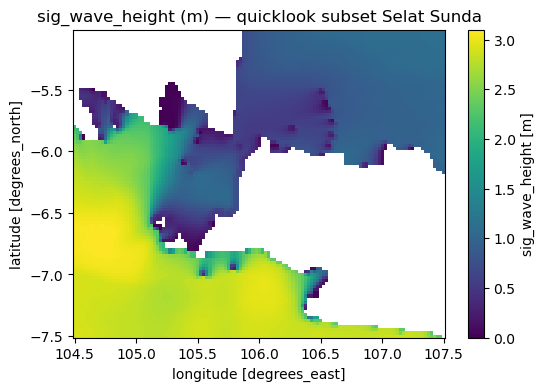

Preview TSTEP: 2026-09-12 09:00:00


In [8]:
# Quicklook bawaan xarray (bukan layout OFS) — crop Selat Sunda dulu
t_idx_preview = int(np.argmin(np.abs(pd.to_datetime(dset["TSTEP"].values) - TARGET_TIME)))
(
    dset["sig_wave_height"]
    .isel(TSTEP=t_idx_preview, LAY=0)
    .sel(ROW=LAT_SLICE, COL=LON_SLICE)
    .plot(figsize=(6, 4))
)
plt.title("sig_wave_height (m) — quicklook subset Selat Sunda")
plt.show()
print("Preview TSTEP:", pd.to_datetime(dset["TSTEP"].values[t_idx_preview]))


## 6. Hands-on Atmos (WRF 2D) untuk angin 10 m

Angin permukaan di Mandala: collection `inacawo_wrf_2d`
(`U_EASTWARD_10M` / `V_NORTHWARD_10M`, **m/s**) — **sama level** dengan OPeNDAP Atmos `uwnd`/`vwnd`.

`inacawo_wrf_3d` menyimpan angin di level tekanan (`U_WIND`); pola spasialnya beda dari 10 m.

Tetap filter tanggal sempit, sama window dengan ocean 2D.


In [9]:
fs.invalidate_cache()
wrf2d_collection = zc.open_collection(
    path="mandala-prod1/datalake/model/collections/inacawo_wrf_2d",
    mode="r",
    filesystem=zc_fs.get_fs(filesystem=fs),
)

dset_wrf = wrf2d_collection.load(delayed=True, filters=date_filter).to_xarray()
print(dset_wrf[["U_EASTWARD_10M", "V_NORTHWARD_10M"]])
print("U_EASTWARD_10M units:", dset_wrf["U_EASTWARD_10M"].attrs.get("units"))
print("standard_name:", dset_wrf["U_EASTWARD_10M"].attrs.get("standard_name"))


<xarray.Dataset>
Dimensions:          (TSTEP: 720, LAY: 1, ROW: 1201, COL: 2201)
Coordinates:
  * TSTEP            (TSTEP) datetime64[ns] 2026-09-01 ... 2026-09-30T23:00:00
  * ROW              (ROW) float64 -15.0 -14.97 -14.95 ... 14.95 14.98 15.0
  * COL              (COL) float64 90.0 90.02 90.05 90.08 ... 144.9 145.0 145.0
Dimensions without coordinates: LAY
Data variables:
    U_EASTWARD_10M   (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
    V_NORTHWARD_10M  (TSTEP, LAY, ROW, COL) float32 dask.array<chunksize=(24, 1, 601, 1101), meta=np.ndarray>
U_EASTWARD_10M units: M/S
standard_name: eastward_wind


## 7. Case study: briefing metocean jalur Selat Sunda

**Skenario.** Sama dengan `opendap-tutorial.ipynb`: forecaster diminta ringkasan singkat
kondisi angin, gelombang, dan arus di jalur Selat Sunda untuk satu waktu forecast.

**Aturan beban:** bbox kecil (`LAT_SLICE`/`LON_SLICE`), 1 waktu, 1–2 variabel per produk —
lalu plot dengan **layout operasional OFS** (logo, title, colorbar, legend arah).


Siapkan slice bersama (waktu + bbox), lalu tiga peta: angin → gelombang → arus.


In [10]:
# Waktu & bbox — selaras case study OPeNDAP (~t+9 jam / 09 UTC dari cycle 00Z 12 Sep 2026)
t_ocean = pd.to_datetime(dset["TSTEP"].values)
t_wrf = pd.to_datetime(dset_wrf["TSTEP"].values)
t_idx = int(np.argmin(np.abs(t_ocean - TARGET_TIME)))
t_idx_wrf = int(np.argmin(np.abs(t_wrf - TARGET_TIME)))
fcst = pd.Timestamp(t_ocean[t_idx]).to_pydatetime()
baserun = datetime(2026, 9, 12, 0, 0)  # cycle referensi (sama konsep OPeNDAP)

atm = (
    dset_wrf[["U_EASTWARD_10M", "V_NORTHWARD_10M"]]
    .isel(TSTEP=t_idx_wrf, LAY=0)
    .sel(ROW=LAT_SLICE, COL=LON_SLICE)
)
wav = (
    dset[["sig_wave_height", "mean_wave_dir"]]
    .isel(TSTEP=t_idx, LAY=0)
    .sel(ROW=LAT_SLICE, COL=LON_SLICE)
)
flo = (
    dset[["u_sur_eastward", "v_sur_northward"]]
    .isel(TSTEP=t_idx, LAY=0)
    .sel(ROW=LAT_SLICE, COL=LON_SLICE)
)

print("Forecast time:", fcst)
print("atm shape:", atm["U_EASTWARD_10M"].shape, "| wav:", wav["sig_wave_height"].shape, "| flo:", flo["u_sur_eastward"].shape)
print("current units:", flo["u_sur_eastward"].attrs.get("units"))


Forecast time: 2026-09-12 09:00:00
atm shape: (100, 121) | wav: (100, 121) | flo: (100, 121)
current units: m s-1


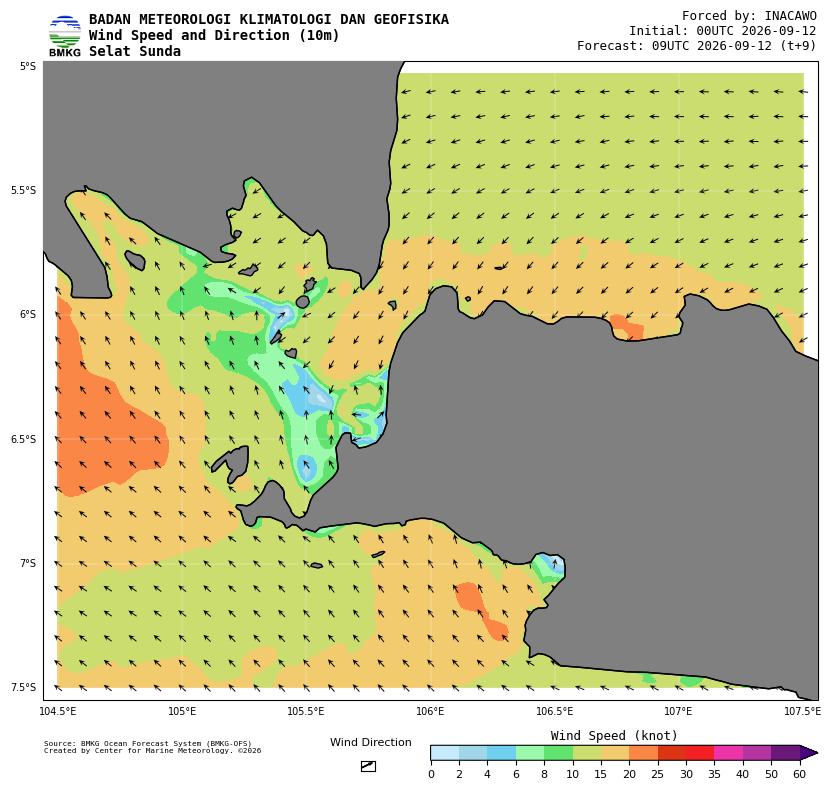

In [11]:
lon_a = atm["COL"].values
lat_a = atm["ROW"].values

fig_ws, ax_ws = plot_ofs_map(
    lon_a,
    lat_a,
    np.sqrt(atm["U_EASTWARD_10M"].values ** 2 + atm["V_NORTHWARD_10M"].values ** 2),
    param="ws",
    u=atm["U_EASTWARD_10M"].values,
    v=atm["V_NORTHWARD_10M"].values,
    wind_in_mps=True,  # Mandala WRF 2D 10 m = m/s (sama OPeNDAP Atmos)
    baserun=baserun,
    forecast=fcst,
    wind_input="INACAWO",
    map_area="Selat Sunda",
    quiver_skip=4,
)
plt.show()

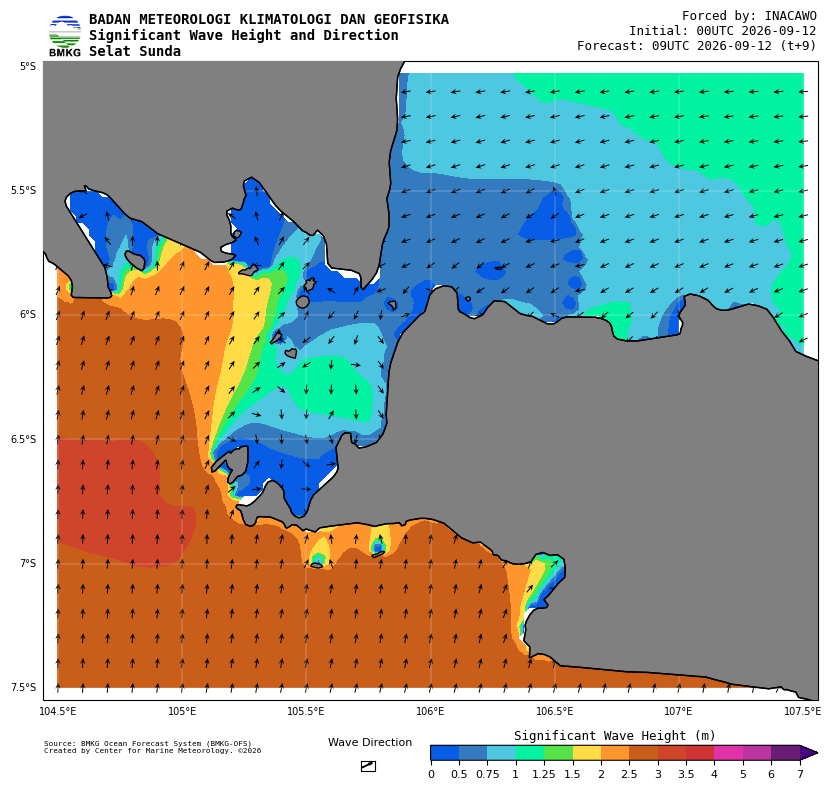

In [12]:
fig_hs, ax_hs = plot_ofs_map(
    wav["COL"].values,
    wav["ROW"].values,
    wav["sig_wave_height"].values,
    param="swh",
    direction=wav["mean_wave_dir"].values,
    wave_dir_convention="meteo_from",  # CF *_from_direction
    baserun=baserun,
    forecast=fcst,
    wind_input="INACAWO",
    map_area="Selat Sunda",
    quiver_skip=4,
)
plt.show()

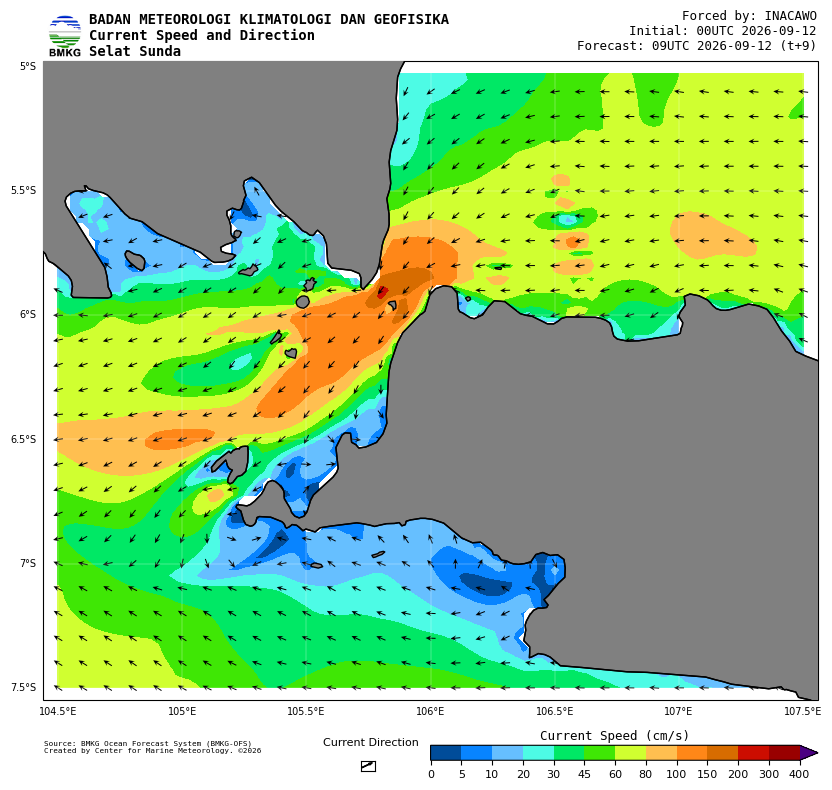

In [13]:
# Mandala u/v permukaan sudah m/s → current_in_mps=True (OPeNDAP Flows biasanya cm/s)
fig_csd, ax_csd = plot_ofs_map(
    flo["COL"].values,
    flo["ROW"].values,
    np.sqrt(flo["u_sur_eastward"].values ** 2 + flo["v_sur_northward"].values ** 2),
    param="csd",
    u=flo["u_sur_eastward"].values,
    v=flo["v_sur_northward"].values,
    current_in_mps=True,
    baserun=baserun,
    forecast=fcst,
    wind_input="INACAWO",
    map_area="Selat Sunda",
    quiver_skip=4,
)
plt.show()

### Interpretasi singkat (isi sendiri saat praktik)

Tulis 3–5 kalimat berdasarkan ketiga peta di atas, misalnya:
- Kekuatan & arah angin dominan di jalur
- Tinggi gelombang signifikan relatif terhadap ambang operasional lokal
- Arus permukaan — apakah mendukung / menentang alur pelayaran

**Catatan arah:** panah mengikuti konvensi helper `ofs-plotter`. Jika membandingkan dengan
sumber lain (termasuk OPeNDAP cycle yang sama), cocokkan dulu apakah arah “from” atau “to”.

## 8. Best practice & catatan lanjutan

**Lakukan**
- Baca langsung S3 + Zarr di Mandalahub (jaringan lokal)
- Filter tanggal / pilih variabel sebelum compute penuh
- Cek `units` & naming sebelum bandingkan dengan OPeNDAP
- Plot case study Selat Sunda (`ws` / `swh` / `csd`) pakai `plot_ofs_map` — sama skenario dengan OPeNDAP
- Cek flag satuan: Mandala angin/arus **m/s** → `wind_in_mps=True`, `current_in_mps=True`

**Hindari**
- Unduh file OPeNDAP penuh lalu upload ke Mandalahub
- Load hindcast multi-tahun tanpa filter
- Hard-code secret S3 di notebook / git

### Tip hindcast `TFLAG`
Pada beberapa collection hindcast, `TFLAG` punya ukuran `VAR` yang berubah antar era.
Jika `load()` gagal dengan *conflicting dimensions*, exclude `TFLAG` via
`selected_variables=[...]` dan tetap filter tanggal sempit.


## 9. Ringkasan jalur akses

| Kebutuhan | Jalur |
|---|---|
| Subset remote cepat / luar Mandalahub | OPeNDAP Hyrax |
| Analisis deret waktu / domain luas di Mandalahub | Mandala S3 + Zarr |
| Plot selaras produk operasional | `training_ofs.plot_ofs_map` (param dari ofs-plotter) |

Parameter plot tersedia: lihat `list_params()` di bawah.


In [14]:
print("OFS plot params:", ", ".join(list_params()))

OFS plot params: csd, csdk, mwh, psh, psp, s, sl, st, swh, vv, wg, wml, wmp, wpl, wpp, ws, wsh, wsp, ww
